# Project 04: KNN Hyperparameter Optimization Lab

## Objective
Build and optimize a K-Nearest Neighbors classifier
for multiclass wine classification.

## Questions We Want to Answer
1. Why does feature scaling matter for KNN?
2. How does the number of neighbors (K) affect performance?
3. Which combination of K and distance weighting works best?
4. Does cross-validation produce a more reliable estimate
   than a single train/test split?

## Techniques
- Exploratory Data Analysis
- Stratified train/test splitting
- StandardScaler and Pipeline
- Stratified K-Fold Cross-Validation
- GridSearchCV
- PCA visualization
- Classification metrics and confusion matrix

## Dataset
The Wine dataset contains chemical measurements from
three wine cultivars.

## Tools
Python, NumPy, Pandas, Matplotlib, Scikit-learn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("KNN Hyperparameter Optimization Lab is ready!")

KNN Hyperparameter Optimization Lab is ready!


In [2]:
# Load the built-in Wine dataset
wine = load_wine(as_frame=True)

# Separate features and target
X = wine.data.copy()
y = wine.target.copy()

# Create a combined DataFrame for exploration
df = X.copy()
df["Target"] = y
df["Class_Name"] = y.map(
    dict(enumerate(wine.target_names))
)

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Number of classes:", y.nunique())

print("\nFeature names:")
print(X.columns.tolist())

print("\nFirst five records:")
display(df.head())

Dataset loaded successfully!
Number of samples: 178
Number of features: 13
Number of classes: 3

Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

First five records:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Target,Class_Name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


In [3]:
print("Class distribution:")
print(
    df["Class_Name"]
    .value_counts()
    .sort_index()
)

print("\nMissing values per column:")
print(X.isnull().sum())

print("\nFeature statistics:")
display(X.describe().T)

print("\nFeature ranges:")
feature_ranges = pd.DataFrame({
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Range": X.max() - X.min()
})

display(feature_ranges.sort_values("Range", ascending=False))

Class distribution:
Class_Name
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64

Missing values per column:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Feature statistics:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00



Feature ranges:


,Minimum,Maximum,Range
proline,278.00,1680.00,1402.00
magnesium,70.00,162.00,92.00
alcalinity_of_ash,10.60,30.00,19.40
color_intensity,1.28,13.00,11.72
malic_acid,0.74,5.80,5.06
flavanoids,0.34,5.08,4.74
alcohol,11.03,14.83,3.80
proanthocyanins,0.41,3.58,3.17
total_phenols,0.98,3.88,2.90
od280/od315_of_diluted_wines,1.27,4.00,2.73


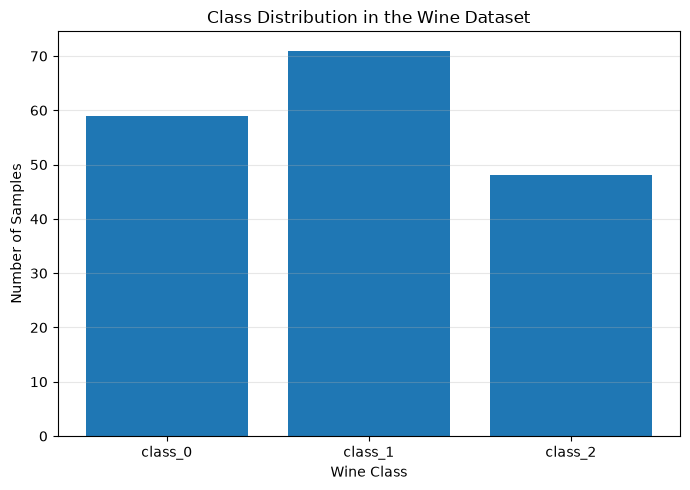

Class_Name
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64

In [4]:
class_counts = df["Class_Name"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    class_counts.index,
    class_counts.values
)

plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.title("Class Distribution in the Wine Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "wine_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(class_counts)

In [5]:
# Scale the features before PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reduce 13 features to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame for plotting
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Class": y.map(dict(enumerate(wine.target_names))).values
})

print("Original number of features:", X.shape[1])
print("Number of PCA components:", X_pca.shape[1])

print(
    "Variance explained by PC1 and PC2:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

display(pca_df.head())

Original number of features: 13
Number of PCA components: 2
Variance explained by PC1 and PC2: 55.41%


,PC1,PC2,Class
0,3.316751,1.443463,class_0
1,2.209465,-0.333393,class_0
2,2.516740,1.031151,class_0
3,3.757066,2.756372,class_0
4,1.008908,0.869831,class_0


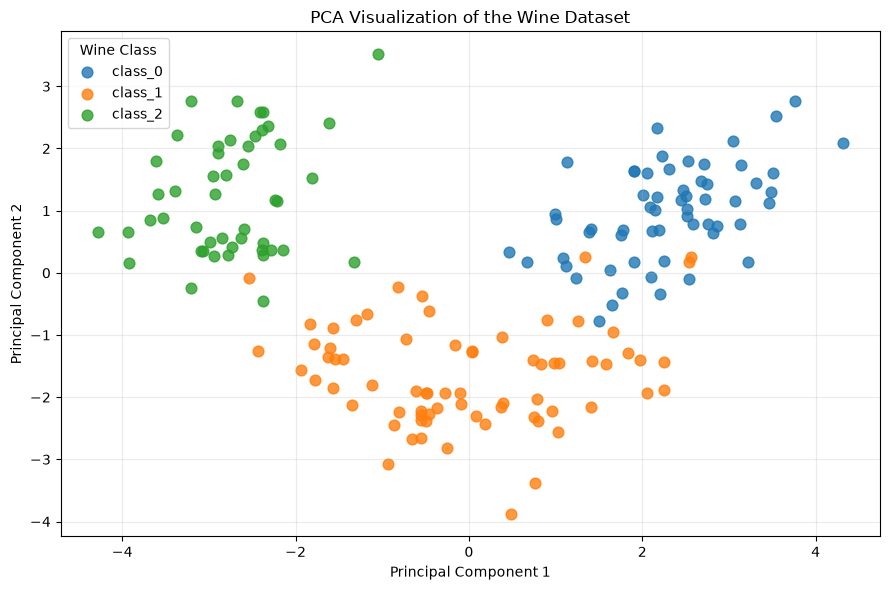

In [6]:
plt.figure(figsize=(9, 6))

for class_name in wine.target_names:
    subset = pca_df[pca_df["Class"] == class_name]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=class_name,
        s=60,
        alpha=0.8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of the Wine Dataset")
plt.legend(title="Wine Class")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "wine_pca_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training samples: 142
Testing samples: 36

Training class distribution:
target
0    47
1    57
2    38
Name: count, dtype: int64

Testing class distribution:
target
0    12
1    14
2    10
Name: count, dtype: int64


In [8]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

print("KNN pipeline created successfully!")

KNN pipeline created successfully!


In [9]:
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Hyperparameter tuning completed!")
print("\nBest parameters:")
print(grid_search.best_params_)

print(
    f"\nBest cross-validation Macro F1: "
    f"{grid_search.best_score_:.4f}"
)

Hyperparameter tuning completed!

Best parameters:
{'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}

Best cross-validation Macro F1: 0.9789


In [10]:
cv_results = pd.DataFrame(grid_search.cv_results_)

top_results = cv_results[
    [
        "param_knn__n_neighbors",
        "param_knn__weights",
        "param_knn__p",
        "mean_test_score",
        "std_test_score",
        "mean_train_score"
    ]
].sort_values("mean_test_score", ascending=False)

top_results = top_results.rename(columns={
    "param_knn__n_neighbors": "K",
    "param_knn__weights": "Weights",
    "param_knn__p": "Distance_P",
    "mean_test_score": "CV_Macro_F1",
    "std_test_score": "CV_Std",
    "mean_train_score": "Train_Macro_F1"
})

display(top_results.head(10).round(4))

,K,Weights,Distance_P,CV_Macro_F1,CV_Std,Train_Macro_F1
9,7,distance,1,0.9789,0.0173,1.0000
8,7,uniform,1,0.9789,0.0173,0.9807
12,9,uniform,1,0.9723,0.0408,0.9826
13,9,distance,1,0.9720,0.0413,1.0000
16,11,uniform,1,0.9656,0.0384,0.9793
22,13,uniform,2,0.9653,0.0389,0.9725
17,11,distance,1,0.9653,0.0389,1.0000
23,13,distance,2,0.9653,0.0389,1.0000
26,15,uniform,2,0.9587,0.0350,0.9724
27,15,distance,2,0.9587,0.0350,1.0000


In [11]:
from sklearn.metrics import f1_score

# Retrieve the best model selected by GridSearchCV
best_knn = grid_search.best_estimator_

# Predictions on training and untouched test data
train_predictions = best_knn.predict(X_train)
test_predictions = best_knn.predict(X_test)

# Calculate evaluation metrics
train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

train_f1 = f1_score(
    y_train, train_predictions, average="macro"
)
test_f1 = f1_score(
    y_test, test_predictions, average="macro"
)

print("=" * 45)
print("KNN MODEL PERFORMANCE")
print("=" * 45)

print(f"Best CV Macro F1: {grid_search.best_score_:.4f}")

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy:     {test_accuracy:.4f}")

print(f"\nTraining Macro F1: {train_f1:.4f}")
print(f"Test Macro F1:     {test_f1:.4f}")

KNN MODEL PERFORMANCE
Best CV Macro F1: 0.9789

Training Accuracy: 0.9789
Test Accuracy:     1.0000

Training Macro F1: 0.9789
Test Macro F1:     1.0000


In [12]:
from sklearn.metrics import f1_score

# Retrieve the best model selected by GridSearchCV
best_knn = grid_search.best_estimator_

# Predictions on training and untouched test data
train_predictions = best_knn.predict(X_train)
test_predictions = best_knn.predict(X_test)

# Calculate evaluation metrics
train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

train_f1 = f1_score(
    y_train, train_predictions, average="macro"
)
test_f1 = f1_score(
    y_test, test_predictions, average="macro"
)

print("=" * 45)
print("KNN MODEL PERFORMANCE")
print("=" * 45)

print(f"Best CV Macro F1: {grid_search.best_score_:.4f}")

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy:     {test_accuracy:.4f}")

print(f"\nTraining Macro F1: {train_f1:.4f}")
print(f"Test Macro F1:     {test_f1:.4f}")

KNN MODEL PERFORMANCE
Best CV Macro F1: 0.9789

Training Accuracy: 0.9789
Test Accuracy:     1.0000

Training Macro F1: 0.9789
Test Macro F1:     1.0000


In [13]:
print("Classification Report — Test Set\n")

print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1, 2],
        target_names=wine.target_names,
        digits=3,
        zero_division=0
    )
)

Classification Report — Test Set

              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        12
     class_1      1.000     1.000     1.000        14
     class_2      1.000     1.000     1.000        10

    accuracy                          1.000        36
   macro avg      1.000     1.000     1.000        36
weighted avg      1.000     1.000     1.000        36



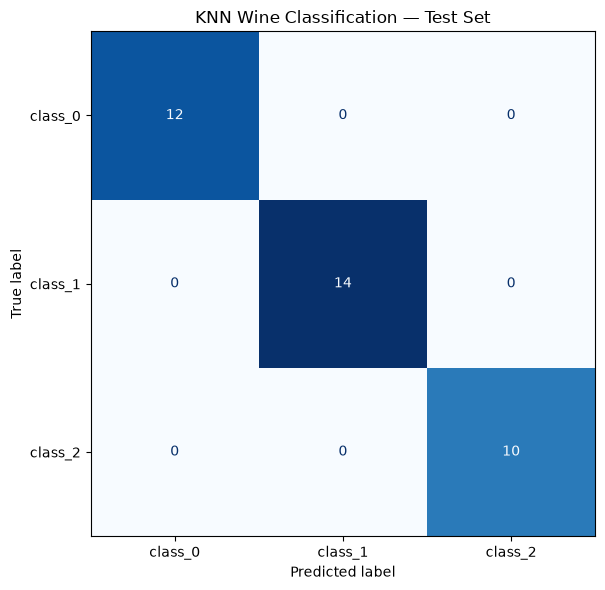

In [14]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=wine.target_names
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("KNN Wine Classification — Test Set")
plt.tight_layout()

plt.savefig(
    "wine_knn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<module 'matplotlib.pyplot' from '/Users/sammy/ai-ml-4-day-build-sprint/.venv/lib/python3.14/site-packages/matplotlib/pyplot.py'>

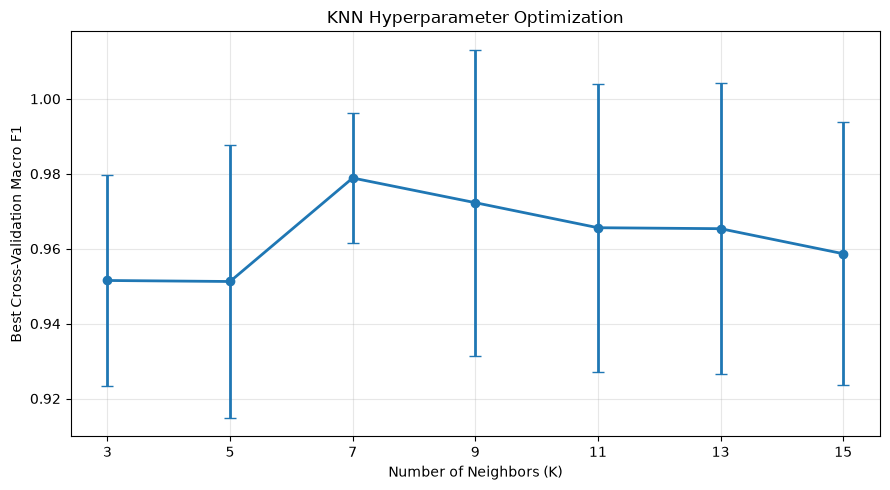

In [15]:
from pathlib import Path

# Find the best combination of distance and weighting
# for each value of K
results_by_k = cv_results.copy()

results_by_k["K"] = (
    results_by_k["param_knn__n_neighbors"].astype(int)
)

best_by_k = (
    results_by_k.loc[
        results_by_k.groupby("K")["mean_test_score"].idxmax()
    ]
    .sort_values("K")
)

plt.figure(figsize=(9, 5))

plt.errorbar(
    best_by_k["K"],
    best_by_k["mean_test_score"],
    yerr=best_by_k["std_test_score"],
    marker="o",
    capsize=4,
    linewidth=2
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Best Cross-Validation Macro F1")
plt.title("KNN Hyperparameter Optimization")
plt.xticks(best_by_k["K"])
plt.grid(alpha=0.3)
plt.tight_layout()

# Save inside the Day 2 folder when running from the repo root
cwd = Path.cwd()

if cwd.name == "day-2-classical-ml":
    output_dir = cwd
elif (cwd / "day-2-classical-ml").is_dir():
    output_dir = cwd / "day-2-classical-ml"
else:
    output_dir = cwd

chart_path = output_dir / "knn_hyperparameter_comparison.png"

plt

In [16]:
print("BEST KNN CONFIGURATION")
print("=" * 35)

print("Best parameters:")
for parameter, value in grid_search.best_params_.items():
    print(f"{parameter}: {value}")

print(f"\nBest CV Macro F1: {grid_search.best_score_:.4f}")
print(f"Test Accuracy:    {test_accuracy:.4f}")
print(f"Test Macro F1:    {test_f1:.4f}")

print("\nSaved project visualizations:")
print("- wine_class_distribution.png")
print("- wine_pca_visualization.png")
print("- wine_knn_confusion_matrix.png")
print("- knn_hyperparameter_comparison.png")

BEST KNN CONFIGURATION
Best parameters:
knn__n_neighbors: 7
knn__p: 1
knn__weights: uniform

Best CV Macro F1: 0.9789
Test Accuracy:    1.0000
Test Macro F1:    1.0000

Saved project visualizations:
- wine_class_distribution.png
- wine_pca_visualization.png
- wine_knn_confusion_matrix.png
- knn_hyperparameter_comparison.png
